# 全部数据的 Likert 分类与分布图

清晰度和流畅度分别按1–5分分类，不合并两项评分。读取Pass、Fail、Uncertain的现有评分，保留Invalid与Human-Uncertain的区别，并与616条原始候选池核对；无评分的数据单列，不能当成0分。

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
import io
def show_figure(fig):
    buffer=io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/raw_data/raw_data.xlsx').exists()), Path.home()/'Desktop/oae')
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'Heiti SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 130
LEVELS = [1,2,3,4,5]
METRICS = {'清晰度':'清晰度评分（1–5）', '流畅度':'流畅度评分（1–5）'}
GROUPS = ['Pass','Fail','Human-Uncertain','Invalid']
COLORS = ['#3274A1','#DF7653','#9A78B5','#89969F']
frames=[]
for folder, filename, label in [('0_PASS','0_PASS.xlsx','Pass'),('1_FAIL','1_FAIL.xlsx','Fail'),('2_Uncertain','2_uncertain.xlsx',None)]:
    source=pd.read_excel(ROOT/'data/labeled_data'/folder/filename)
    part=source[['ID',*METRICS.values()]].copy()
    part['类别']=source['secondary_category'] if label is None else label
    frames.append(part)
data=pd.concat(frames,ignore_index=True)
assert not data.ID.isna().any() and not data.ID.duplicated().any()
assert data['类别'].isin(GROUPS).all()
for column in METRICS.values():
    data[column]=pd.to_numeric(data[column],errors='raise')
    assert data[column].isin(LEVELS).all(), f'{column}存在缺失或非法值'
    data[column]=data[column].astype(int)
raw=pd.read_excel(ROOT/'data/raw_data/raw_data.xlsx')
assert not raw.ID.duplicated().any()
assert set(data.ID)<=set(raw.ID)
missing=raw.loc[~raw.ID.isin(data.ID),['ID','eligibility']].copy()
missing=missing.rename(columns={'eligibility':'原始资格分类'})
missing['评分状态']='未评分'
coverage=data.groupby('类别').size().reindex(GROUPS,fill_value=0).rename('已评分数量').to_frame()
coverage.loc['已评分合计']=len(data)
coverage.loc['未评分']=len(missing)
coverage.loc['候选池合计']=len(raw)
assert len(data)+len(missing)==len(raw)
display(coverage)
print('未评分的视频：')
display(missing)


,已评分数量
类别,
Pass,304
Fail,47
Human-Uncertain,7
Invalid,245
已评分合计,603
未评分,13
候选池合计,616


未评分的视频：


,ID,原始资格分类,评分状态
3,C0004,Invalid,未评分
17,C0018,Invalid,未评分
115,C0116,Invalid,未评分
129,C0130,Invalid,未评分
199,C0200,Invalid,未评分
213,C0214,Invalid,未评分
227,C0228,Invalid,未评分
234,C0235,Invalid,未评分
241,C0242,Invalid,未评分
245,C0246,Invalid,未评分


## Likert等级分类表

In [5]:
tables={}
for metric,column in METRICS.items():
    counts=pd.crosstab(data[column],data['类别']).reindex(index=LEVELS,columns=GROUPS,fill_value=0)
    table=pd.DataFrame(index=pd.Index(LEVELS,name='Likert等级'))
    for group in GROUPS:
        table[group+'数量']=counts[group]
        table[group+'占比']=counts[group]/(data['类别']==group).sum()
    table['总体数量']=counts.sum(axis=1)
    table['总体占比']=table['总体数量']/len(data)
    assert table['总体数量'].sum()==len(data)
    tables[metric]=table
    print(metric)
    display(table.style.format({c:'{:.1%}' for c in table if '占比' in c}))


清晰度


,Pass数量,Pass占比,Fail数量,Fail占比,Human-Uncertain数量,Human-Uncertain占比,Invalid数量,Invalid占比,总体数量,总体占比
Likert等级,,,,,,,,,,
1,0,0.0%,0,0.0%,0,0.0%,0,0.0%,0,0.0%
2,0,0.0%,1,2.1%,0,0.0%,7,2.9%,8,1.3%
3,76,25.0%,10,21.3%,0,0.0%,26,10.6%,112,18.6%
4,119,39.1%,19,40.4%,7,100.0%,212,86.5%,357,59.2%
5,109,35.9%,17,36.2%,0,0.0%,0,0.0%,126,20.9%


流畅度


,Pass数量,Pass占比,Fail数量,Fail占比,Human-Uncertain数量,Human-Uncertain占比,Invalid数量,Invalid占比,总体数量,总体占比
Likert等级,,,,,,,,,,
1,0,0.0%,0,0.0%,0,0.0%,0,0.0%,0,0.0%
2,0,0.0%,8,17.0%,0,0.0%,4,1.6%,12,2.0%
3,32,10.5%,25,53.2%,0,0.0%,31,12.7%,88,14.6%
4,154,50.7%,11,23.4%,3,42.9%,134,54.7%,302,50.1%
5,118,38.8%,3,6.4%,4,57.1%,76,31.0%,201,33.3%


## 图1：总体Likert分布
柱顶显示数量与占比；不包括未评分视频。

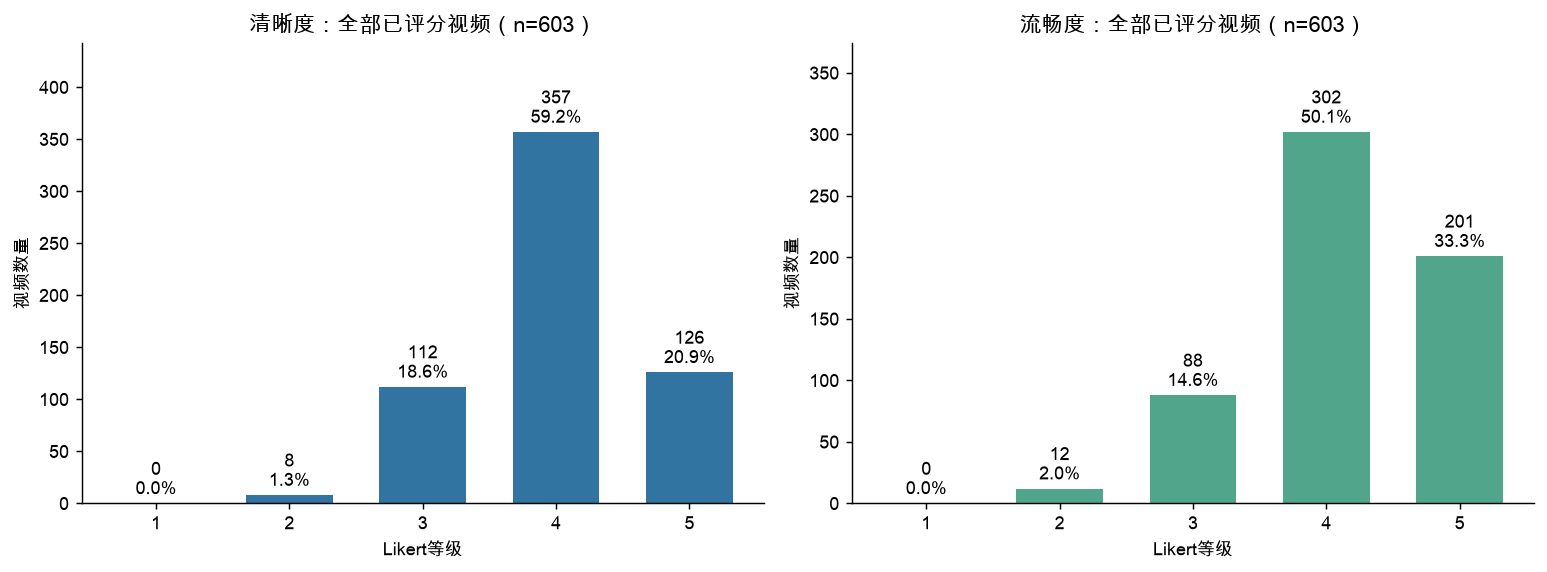

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,(metric,table),color in zip(axes,tables.items(),['#3274A1','#51A58A']):
    values=table['总体数量']
    ax.bar(LEVELS,values,color=color,width=.65)
    for level,count in values.items():
        ax.text(level,count+max(values.max()*.025,1),f'{count}\n{count/len(data):.1%}',ha='center',fontsize=10)
    ax.set(title=f'{metric}：全部已评分视频（n={len(data)}）',xlabel='Likert等级',ylabel='视频数量',xticks=LEVELS)
    ax.set_ylim(0,max(values.max()*1.24,1))
    ax.spines[['top','right']].set_visible(False)
fig.tight_layout();show_figure(fig);plt.close(fig)


## 图2：各类别的等级比例
采用类别内部占比，避免不同类别样本数量影响比较。

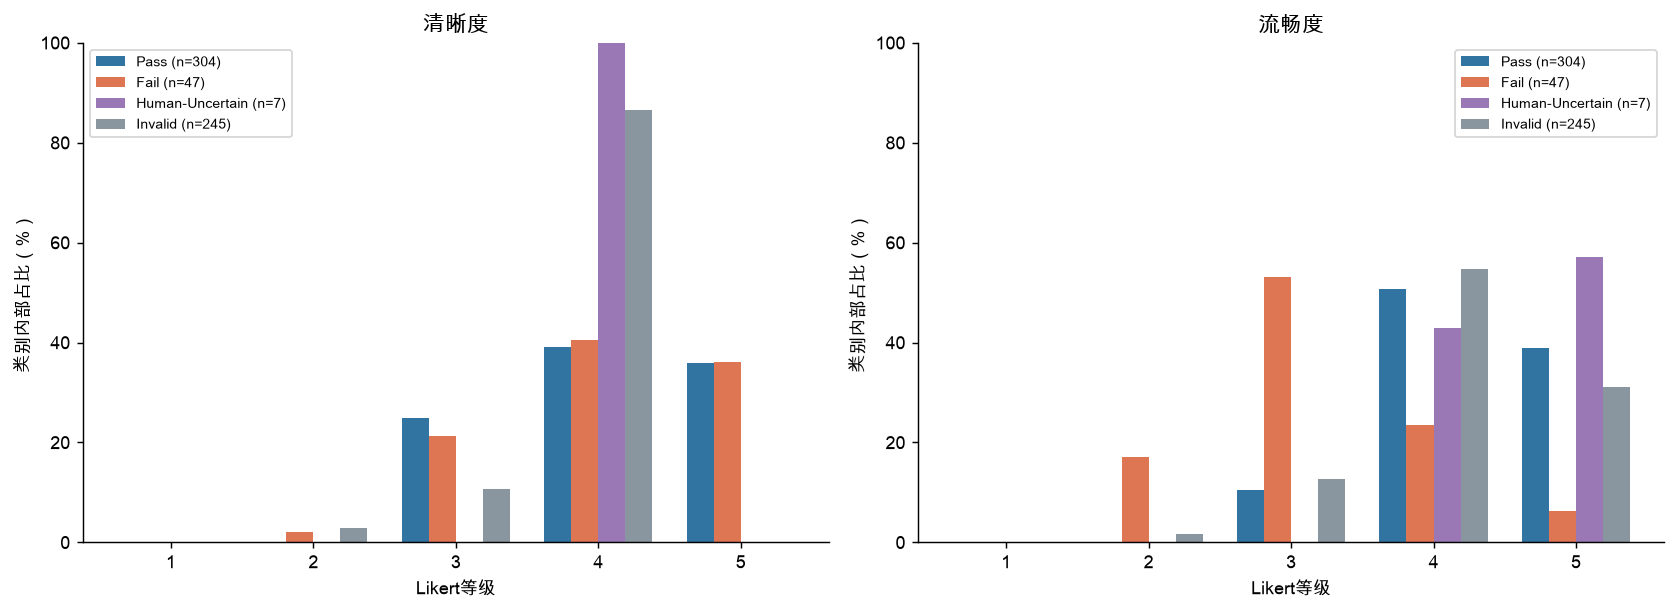

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
x=np.arange(5);width=.19
for ax,(metric,column) in zip(axes,METRICS.items()):
    for j,(group,color) in enumerate(zip(GROUPS,COLORS)):
        part=data.loc[data['类别']==group,column]
        pct=part.value_counts().reindex(LEVELS,fill_value=0)/len(part)*100
        ax.bar(x+(j-1.5)*width,pct,width,label=f'{group} (n={len(part)})',color=color)
    ax.set(title=metric,xlabel='Likert等级',ylabel='类别内部占比（%）',xticks=x,xticklabels=LEVELS,ylim=(0,100))
    ax.legend(fontsize=8);ax.spines[['top','right']].set_visible(False)
fig.tight_layout();show_figure(fig);plt.close(fig)


## 图3：清晰度与流畅度交叉分布
单元格显示视频数量。两项评分分别保留。

流畅度评分（1–5）,1,2,3,4,5
清晰度评分（1–5）,,,,,
1,0,0,0,0,0
2,0,2,4,2,0
3,0,5,18,87,2
4,0,5,53,187,112
5,0,0,13,26,87


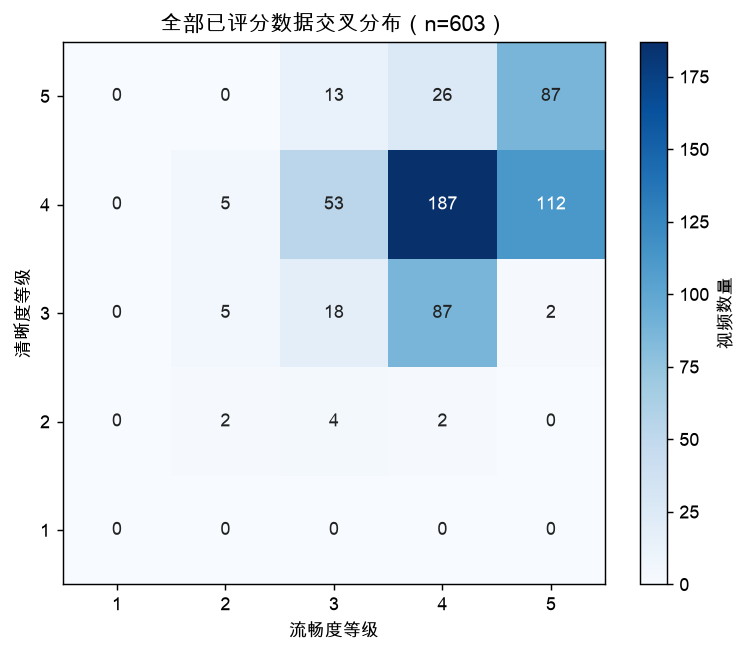

In [14]:
joint=pd.crosstab(data[METRICS['清晰度']],data[METRICS['流畅度']]).reindex(index=LEVELS,columns=LEVELS,fill_value=0)
assert joint.to_numpy().sum()==len(data)
display(joint)
fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(joint,cmap='Blues',origin='lower')
for i in range(5):
    for j in range(5):
        v=int(joint.iloc[i,j]);ax.text(j,i,str(v),ha='center',va='center',color='white' if v>joint.to_numpy().max()/2 else '#222222')
ax.set(xticks=range(5),xticklabels=LEVELS,yticks=range(5),yticklabels=LEVELS,xlabel='流畅度等级',ylabel='清晰度等级',title=f'全部已评分数据交叉分布（n={len(data)}）')
fig.colorbar(im,ax=ax,label='视频数量');fig.tight_layout();show_figure(fig);plt.close(fig)
